# Day 27 · New tool — Reaching into 1987
### #30DayMapChallenge 2026 · ARCO-ERA5 (cloud-native Zarr) · Map by Emma Pidduck

The new tool here isn't a library — it's a **way of holding data**. The entire **ERA5 reanalysis**
— 1959 to now, dozens of variables, hourly, global, *petabytes* — sits in a public cloud bucket as
**analysis-ready Zarr**. You don't download it. You open it like one array and reach in for the
exact slice you want.

To prove it, this map pulls a single hour from nearly **40 years ago**: the **Great Storm of
16 October 1987**, the explosive cyclone that tore across southern England overnight, killed 18
people and felled 15 million trees — the one Michael Fish had, the afternoon before, told the
nation not to worry about.

## Method

- Open **ARCO-ERA5** (Analysis-Ready, Cloud-Optimised ERA5, published by Google on GCS) with
  `xarray.open_zarr` — no credentials, no download, just a URL.
- **Random-access** one timestamp, `1987-10-16 06 UTC`, and a window over the British Isles —
  two variables, `10m_wind_speed` and `mean_sea_level_pressure`. One `.sel(...).compute()` pulls
  only the handful of chunks that intersect that request: a few megabytes out of a petabyte.
- Shade 10 m wind; overlay MSLP isobars every 4 hPa; mark the storm's centre.

**Why this is the "new tool":** every other day in this series downloads a GRIB file first. Here
there is no file. The cube is remote, chunked, and lazily read — the model only touches the bytes
it needs. That is what makes a petabyte archive usable from a laptop.

## Licence & attribution

**ERA5** is produced by **ECMWF** for the **Copernicus Climate Change Service (C3S)**.
**ARCO-ERA5** is a cloud-optimised mirror hosted by **Google** (`gs://gcp-public-data-arco-era5`),
publicly readable.

> Contains modified Copernicus Climate Change Service information. Generated using Copernicus
> Climate Change Service information; neither the European Commission nor ECMWF is responsible
> for any use of the Copernicus information.

ARCO-ERA5: Carver & Merose (2023). ERA5: Hersbach et al. (2020), *QJRMS*.

## Tools

| Tool | Role |
|---|---|
| [`xarray`](https://xarray.dev) + [`zarr`](https://zarr.readthedocs.io) | open the remote cube, lazily |
| [`gcsfs`](https://gcsfs.readthedocs.io) | read Google Cloud Storage anonymously |
| `cartopy` · `matplotlib` | projection, isobars, the storm render |

New dependencies versus the forecast days: **`zarr`** and **`gcsfs`**. No account, no key —
the bucket is public (`token="anon"`).

In [1]:
# Run once if needed (uncomment):
#!pip install zarr gcsfs xarray cartopy matplotlib

In [2]:
import time, warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, to_rgba
import cartopy.crs as ccrs
import cartopy.feature as cfeature
warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
BG, INK, MUT = "#ffffff", "#1d2230", "#6b7280"

### Configuration

Change `WHEN` to reach for any other hour in the record — the 2003 heatwave, the 1976 drought,
Storm Daria (Jan 1990). The read cost barely moves: you only ever pull the chunks you touch.

In [3]:
URL  = "gs://gcp-public-data-arco-era5/ar/1959-2022-6h-1440x721.zarr"
WHEN = "1987-10-16T06:00"      # the Great Storm, near its deepest over England
WIN  = dict(longitude=slice(-18, 14), latitude=slice(62, 42))

## Open the cloud cube and reach in

The whole archive is one `open_zarr`. The `.sel(...).compute()` is where bytes actually move —
and only for the slice requested.

In [4]:
t0 = time.time()
ds = xr.open_zarr(URL, storage_options={"token": "anon"})
# longitudes are 0..360; roll to -180..180 so a UK/France window doesn't straddle the seam
ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180)).sortby("longitude")
sub = ds[["10m_wind_speed", "mean_sea_level_pressure"]].sel(time=WHEN, **WIN).compute()
dt = time.time() - t0

ws   = sub["10m_wind_speed"]
mslp = sub["mean_sea_level_pressure"] / 100.0
lon, lat = ws.longitude.values, ws.latitude.values
print(f"opened the archive and pulled one hour in {dt:.1f} s")
print(f"window {dict(ws.sizes)}   wind to {float(ws.max()):.1f} m/s   lowest MSLP {float(mslp.min()):.1f} hPa")

opened the archive and pulled one hour in 23.2 s
window {'latitude': 81, 'longitude': 129}   wind to 27.2 m/s   lowest MSLP 957.9 hPa


In [5]:
# locate the storm centre (grid minimum of MSLP)
j = np.unravel_index(int(mslp.values.argmin()), mslp.shape)
lo_lat, lo_lon, lo_p = float(lat[j[0]]), float(lon[j[1]]), float(mslp.values[j])
print(f"low centre: {lo_p:.0f} hPa at {lo_lat:.1f}N {abs(lo_lon):.1f}{'W' if lo_lon<0 else 'E'}")

low centre: 958 hPa at 53.5N 0.8W


### Colour — calm → storm, colourblind-safe

Pale (calm) to deep indigo (fierce). **Monotonic in luminance** (verified), so wind speed reads
by brightness alone for every colour-vision type — and it keeps the house white background.

In [6]:
CMAP = LinearSegmentedColormap.from_list("storm", [
    "#fbfcfe", "#dcebf3", "#9fd0db", "#56b0c6", "#2f7fb8", "#3a4fa0", "#3b2f7a", "#241a4d"])
rgb = np.array([to_rgba(CMAP(t))[:3] for t in np.linspace(0, 1, 256)])
lum = 0.2126*rgb[:,0] + 0.7152*rgb[:,1] + 0.0722*rgb[:,2]
mono = (np.diff(lum) <= 1e-3).all() or (np.diff(lum) >= -1e-3).all()
print("storm ramp luminance-monotonic:", bool(mono), f"({lum[0]:.2f} -> {lum[-1]:.2f})")

storm ramp luminance-monotonic: True (0.99 -> 0.12)


## Render

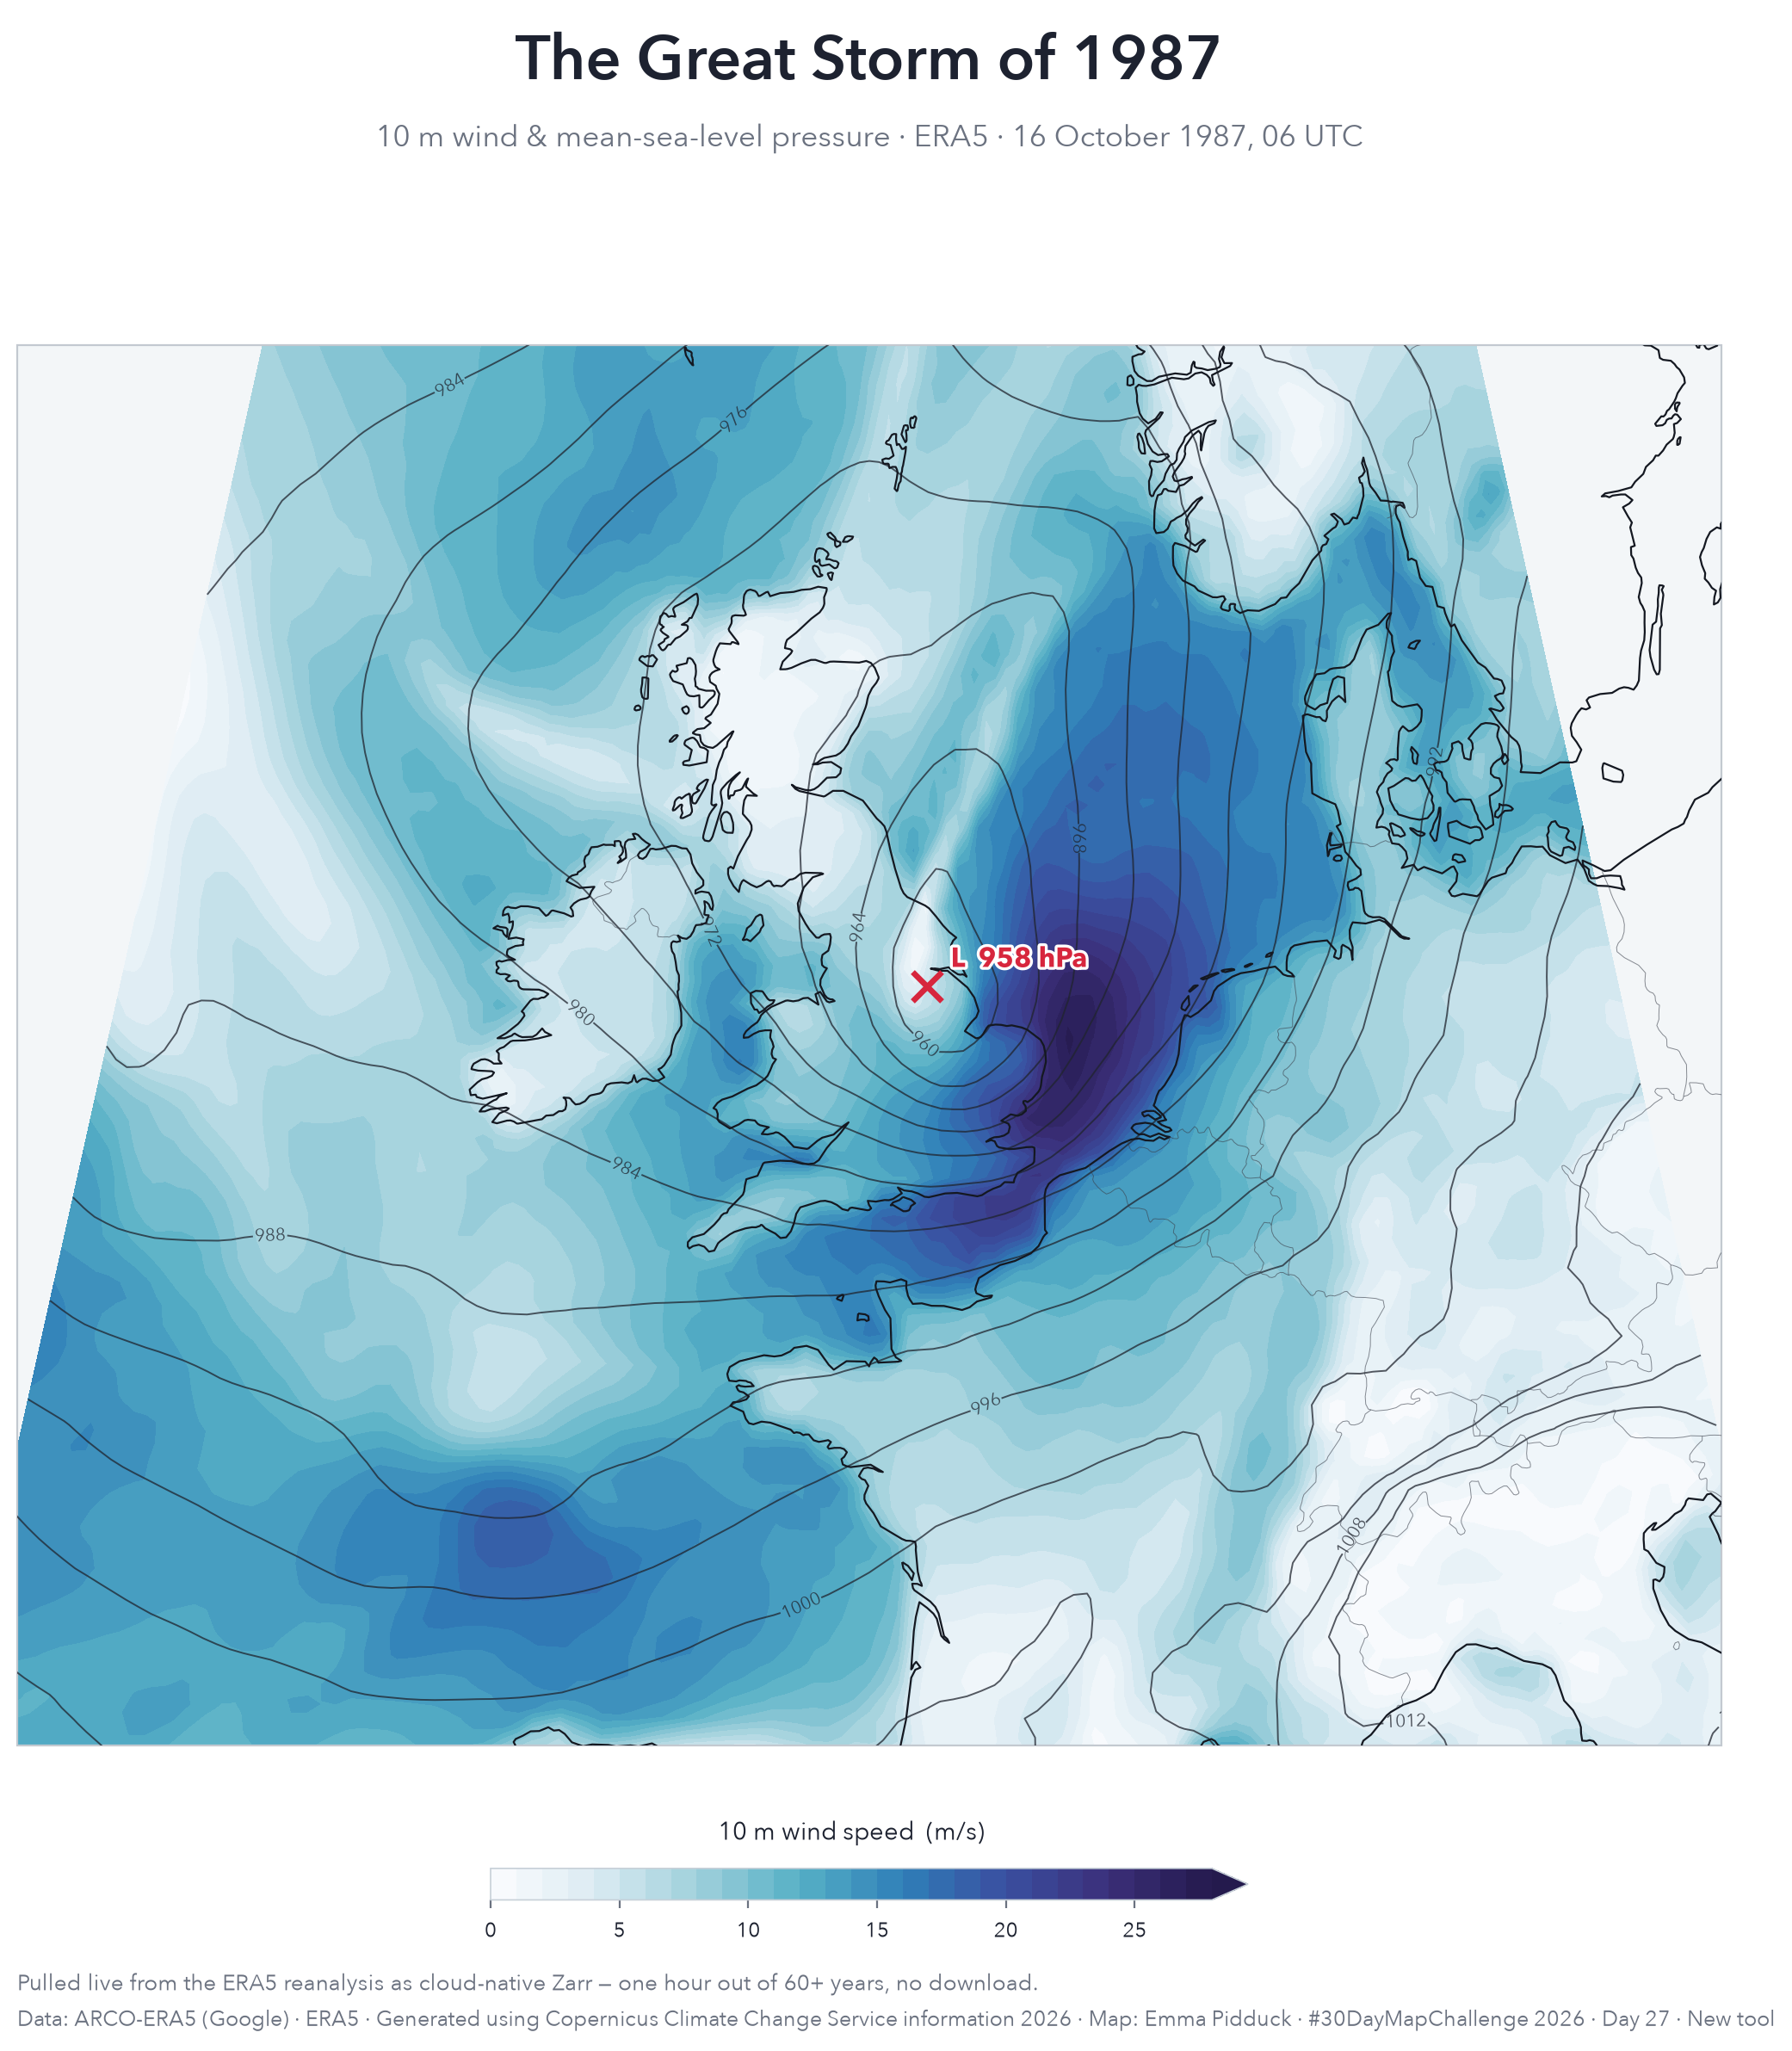

In [7]:
proj = ccrs.LambertConformal(central_longitude=-2, central_latitude=52, standard_parallels=(45, 58))
tp = dict(transform=ccrs.PlateCarree())
fig = plt.figure(figsize=(11, 12.2), dpi=200); fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.05, 0.095, 0.90, 0.80], projection=proj)
ax.set_extent([-17, 13, 43, 61], crs=ccrs.PlateCarree()); ax.set_facecolor("#f3f6f8")

cf = ax.contourf(lon, lat, ws.values, levels=np.arange(0, 28.1, 1.0), cmap=CMAP, extend="max", zorder=0, **tp)
cs = ax.contour(lon, lat, mslp.values, levels=np.arange(936, 1041, 4),
                colors="#20242e", linewidths=0.7, alpha=0.75, zorder=3, **tp)
ax.clabel(cs, fmt="%d", fontsize=7.5, inline=True, inline_spacing=2)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="#141821", linewidth=0.8, zorder=4)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#3a3f4a", linewidth=0.35, alpha=0.6, zorder=4)
ax.spines["geo"].set_edgecolor("#c3c9d0"); ax.spines["geo"].set_linewidth(0.8)

halo = [pe.withStroke(linewidth=2.4, foreground="white")]
ax.plot(lo_lon, lo_lat, marker="x", ms=12, mew=2.4, color="#d7263d", transform=ccrs.PlateCarree(), zorder=6)
ax.annotate(f"L  {lo_p:.0f} hPa", (lo_lon, lo_lat), xytext=(10, 8), textcoords="offset points",
            transform=ccrs.PlateCarree(), fontsize=11.5, fontweight="bold", color="#d7263d",
            zorder=6, path_effects=halo)

cax = fig.add_axes([0.30, 0.088, 0.40, 0.015])
cb = fig.colorbar(cf, cax=cax, orientation="horizontal", extend="max", ticks=[0,5,10,15,20,25])
cb.set_label("10 m wind speed  (m/s)", color=INK, fontsize=10.5, labelpad=12)
cb.ax.xaxis.set_label_position("top")
cb.ax.xaxis.set_tick_params(color=MUT, labelsize=8.5); plt.setp(plt.getp(cb.ax,"xticklabels"), color=INK)
cb.outline.set_edgecolor("#c7d0d8"); cb.outline.set_linewidth(0.6)

fig.text(0.5, 0.955, "The Great Storm of 1987", ha="center", color=INK, fontsize=26, fontfamily=["Avenir Next Demi Bold", "Arial", "DejaVu Sans"])
fig.text(0.5, 0.923, "10 m wind & mean-sea-level pressure · ERA5 · 16 October 1987, 06 UTC",
         ha="center", color=MUT, fontsize=12.5)
fig.text(0.05, 0.045, "Pulled live from the ERA5 reanalysis as cloud-native Zarr — one hour out of 60+ years, no download.",
         color=MUT, fontsize=9.3)
fig.text(0.05, 0.028, "Data: ARCO-ERA5 (Google) · ERA5 · Generated using Copernicus Climate Change Service information 2026 · Map: Emma Pidduck · #30DayMapChallenge 2026 · Day 27 · New tool",
         color=MUT, fontsize=9)
fig.savefig("day27_new_tool_zarr.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Note

ERA5 at 0.25° resolves the low to about **958 hPa**; surface observations on the night put it
nearer **953 hPa**. The tell-tale signature of a damaging windstorm is here: the strongest 10 m
winds are **not** at the centre but on its **southern flank** — the dark band sweeping the English
Channel, south-east England and the Low Countries, which is exactly where the destruction fell.

The point of the day is the plumbing. Forty years of a petabyte archive, and the map above cost
one `open_zarr` and one `.sel`. **Zarr + object storage** is how climate data is increasingly
served — ARCO-ERA5, the Copernicus EWC, Pangeo, dynamical.org — and it changes what you can do
from a laptop.

**Saved:** `day27_new_tool_zarr.png` — ready to post.

*A fourth way to get ECMWF data, after the IFS open-data GRIBs, MeteoSwiss ICON-CH1, and the
Copernicus CDS. Day 2 Lines · Day 6 Vintage · Day 20 Hexagons · Day 22 Projections · Day 26
Water · Day 28 Feeling.*